# Calendario e intensidades: de buckets a integración del tiempo de default
Continuidad de CICLO29: antes se suministraban probabilidades exclusivas por período genérico; no se podía cambiar de calendario sin volver a especificarlas. Ahora usamos intensidades anuales por tramos y conservamos la API original sin reinterpretar sus argumentos. Novedad: adaptación local y verificación; las identidades de riesgos competidores son conocidas.

Pregunta: ¿cuánto sesgo introduce descontar todos los defaults al cierre de cada bucket? H preespecificada: >2% a un año, λd=.24, λp=1.2 y fuerza de descuento ρ=.06. Datos enteramente sintéticos.

## 1. Fórmula original y derivación
En el modelo discreto, $D_i=S_{i-1}d_i$, $P_i=S_{i-1}p_i$, $S_i=S_{i-1}(1-d_i-p_i)$ y $EL_{end}=\sum_i D_i E_iL e^{-\rho t_i}$, con EAD condicional $E_i$ y LGD $L$.

Suponga intensidades constantes dentro del intervalo: $\lambda_d,\lambda_p$ en año$^{-1}$ y $\Delta_i$ en años. La ecuación $dS(u)/du=-k_iS(u)$, $k_i=\lambda_d+\lambda_p$, implica $S(u)=S_{i-1}e^{-k_i u}$. Integrar $\lambda_d S(u)$ da $d_i=\lambda_d(1-e^{-k_i\Delta_i})/k_i$ y análogamente $p_i$. La supervivencia es $e^{-k_i\Delta_i}$. Si $k_i=0$ ambas salidas son cero. No dividir una probabilidad anual por doce. Tampoco convertir cada salida con $1-e^{-\lambda\Delta}$ por separado: suma mal las masas conjuntas.

Esta conversión obtiene probabilidades de **salidas competidoras**, no asume que ambos eventos puedan ocurrir.

## 2. Propuesta: descuento dentro del intervalo
Si el default ocurre a tiempo $u$ del intervalo, descontar a $t_{i-1}+u$ en lugar del cierre:
$$EL_i=S_{i-1}E_iL e^{-\rho t_{i-1}}\int_0^{\Delta_i}\lambda_d e^{-(k_i+\rho)u}du
=S_{i-1}E_iL e^{-\rho t_{i-1}}\frac{\lambda_d}{k_i+\rho}(1-e^{-(k_i+\rho)\Delta_i}).$$
Unidades: integral y masas adimensionales, EAD en dinero y LGD fracción. `src/calendar.py` usa `expm1` para evitar cancelación cerca de cero; `integrated` corresponde al cociente/integral, `exact` a cada ELi y `endpoint` al baseline. Para $k+\rho=0$, λd=0 y pérdida cero. Ambos modelos comparten probabilidades, horizonte, EAD y tasa: solo cambia tiempo de descuento. No se modifica ni descalifica el baseline discreto29.

ρ≥0 implica $EL_{end}\le EL_{exact}$ pues $e^{-\rho\Delta}\le e^{-\rho u}$. Para coeficientes constantes, partir un intervalo no cambia la integral exacta por aditividad; sí reduce el sesgo del cierre. No es prueba de calibración ni teorema sobre datos reales.

In [1]:
from pathlib import Path
root=Path.cwd()
from src.calendar import project_calendar
import csv,json,math
from IPython.display import display,Image
print(json.dumps(json.loads((root/'results/calendar_metrics.json').read_text()),indent=2))
rows=list(csv.DictReader((root/'results/calendar.csv').open()))
for r in rows: print(r)

{
  "config": {
    "dataset": "synthetic constant intensities, not fitted loans",
    "horizon_years": 1,
    "default_hazard": 0.24,
    "prepay_hazard": 1.2,
    "ead": 100,
    "lgd": 0.45,
    "discount_forces": [
      0.06,
      0.0,
      0.2
    ],
    "partitions": [
      1,
      2,
      4,
      12,
      52,
      360
    ],
    "seed": null,
    "hypothesis": "annual endpoint loss underestimates exact integrated loss by >2% at rho .06",
    "hardware": "recorded in inherited results/metrics.json",
    "units": "hazards and discount force year^-1; duration years; exposure money"
  },
  "seconds": 0.02499261100001604,
  "peak_bytes": 68308,
  "hypothesis": true
}
{'discount_force': '0.06', 'intervals': '1', 'relative_endpoint_bias': '-0.0364184140910887', 'default_probability': '0.12717870688631303', 'prepayment_probability': '0.6358935344315652', 'survival': '0.23692775868212176', 'exact_loss': '5.593462846931305', 'endpoint_loss': '5.389757800768641'}
{'discount_force'

## 3. Ejecución y sensibilidad
Un año, EAD100, LGD.45, intensidades .24/1.2. Tasas0,.06,.20 y 1,2,4,12,52,360 intervalos. Mismos parámetros anuales; no se cambia el DGP entre calendarios. Tabla cruda muestra ambas pérdidas y masa total.

Invariancia exacta: 8.881784197001252e-16


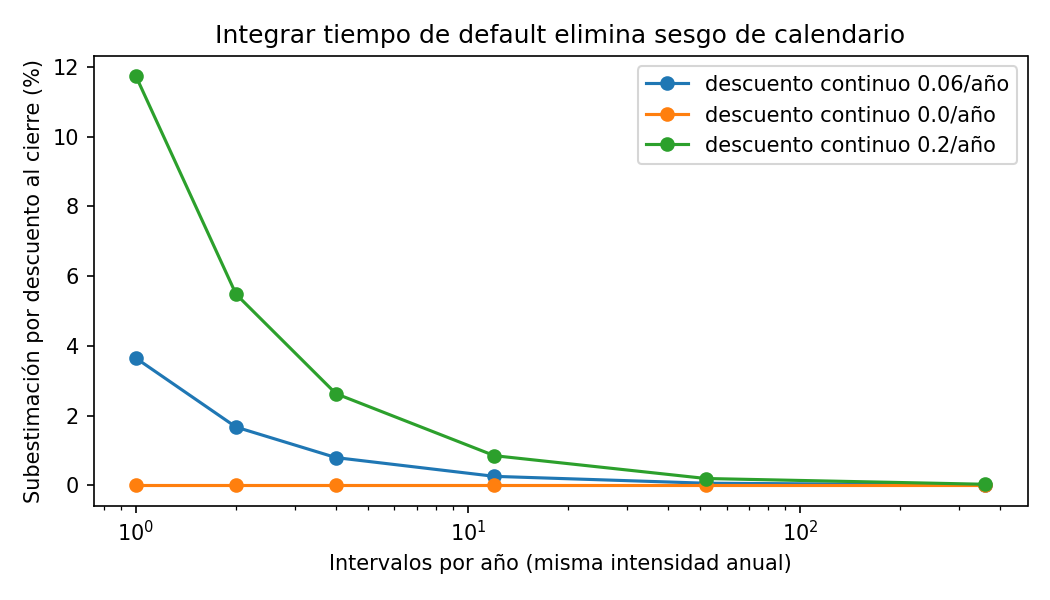

In [2]:
display(Image(filename=str(root/'results/calendar.png')))
one=project_calendar([1.],[.24],[1.2],[100.])
monthly=project_calendar([1/12]*12,[.24]*12,[1.2]*12,[100.]*12)
print('Invariancia exacta:',abs(one.exact_loss-monthly.exact_loss))
assert abs(one.exact_loss-monthly.exact_loss)<1e-12
assert one.endpoint_loss<one.exact_loss

## 4. Casos negativos y límite de la mejora
Con descuento cero ambos coinciden: no se fabrica mejora. Con default cero, pérdida cero. La invariancia de partición exige EAD/intensidades constantes dentro del tramo; al refinar una trayectoria amortizable no debe cambiarse silenciosamente esa función. La mejora es exactitud bajo supuestos, no mayor capacidad predictiva. H1 ya no implica misma pérdida al variar intensidad prepago: esta API continua tiene eventos en tiempos distintos y no reinterpreta el negativo de la API discreta29.

No se estima dependencia de covariables, censura, errores de calibración ni probabilidad de prepago a datos. No usar cifras para provisiones regulatorias. Fórmula conocida adaptada a calendario explícito; `benchmarks/prior-art.md` clasifica cinco trabajos y `research-log.md` conserva elección y siguiente prueba.

In [3]:
zero=project_calendar([1.],[.24],[1.2],[100.],discount_force=0.)
assert abs(zero.exact_loss-zero.endpoint_loss)<1e-12
print('Sin descuento:',zero)
print((root/'results/tests.txt').read_text())

Sin descuento: CalendarResult(default_probability=0.12717870688631303, prepayment_probability=0.6358935344315652, survival=0.23692775868212176, exact_loss=5.723041809884086, endpoint_loss=5.723041809884086)
test_closed_form (test_calendar.CalendarTests.test_closed_form) ... ok
test_invalid (test_calendar.CalendarTests.test_invalid) ... ok
test_invalid_bounds (test_calendar.CalendarTests.test_invalid_bounds) ... ok
test_negative_zero_discount (test_calendar.CalendarTests.test_negative_zero_discount) ... ok
test_partition_and_mass (test_calendar.CalendarTests.test_partition_and_mass) ... ok
test_refinement (test_calendar.CalendarTests.test_refinement) ... ok
test_invalid (test_model.TestProjection.test_invalid) ... ok
test_mass_absorbing_and_zero_exposure (test_model.TestProjection.test_mass_absorbing_and_zero_exposure) ... ok
test_monotone_prepay_discount_and_scaling (test_model.TestProjection.test_monotone_prepay_discount_and_scaling) ... ok
test_rational_oracle (test_model.TestProject